# Diamond Price Outlier Analysis
## Seaborn Session 4 – Boxplot & Violin Plot

This project analyzes diamond prices, identifies outliers using the IQR method, and compares boxplots with violin plots.

Task 1: Load diamonds dataset and create boxplot

       carat        cut color clarity  depth  table  price     x     y     z
1388    0.24      Ideal     G    VVS1   62.1   56.0    559  3.97  4.00  2.47
50052   0.58  Very Good     F    VVS2   60.0   57.0   2201  5.44  5.42  3.26
41645   0.40      Ideal     E    VVS2   62.1   55.0   1238  4.76  4.74  2.95
42377   0.43    Premium     E    VVS2   60.8   57.0   1304  4.92  4.89  2.98
17244   1.55      Ideal     E     SI2   62.3   55.0   6901  7.44  7.37  4.61
Total Records: 5000


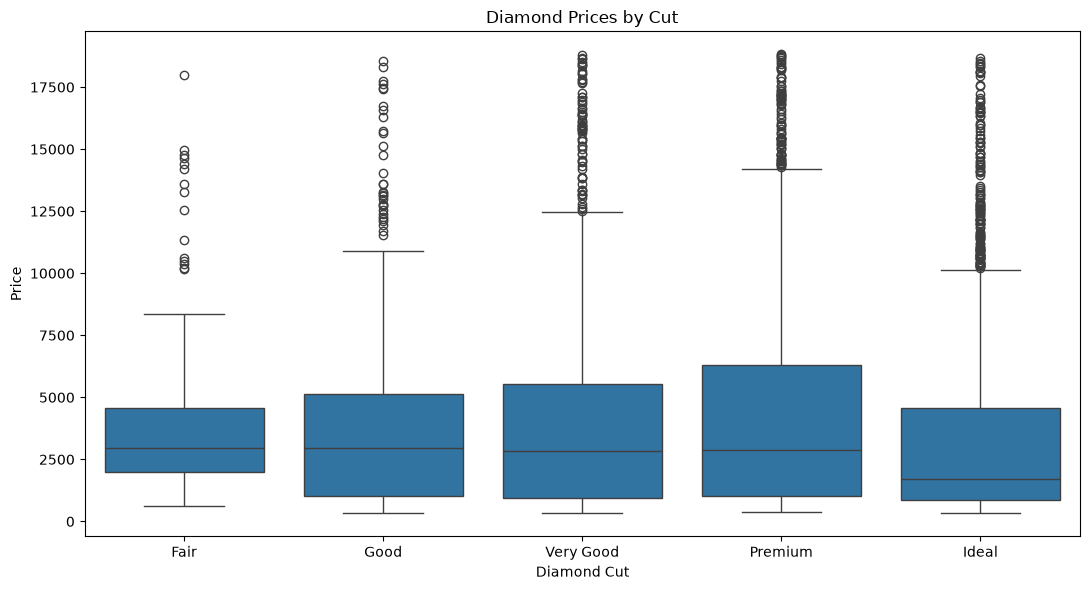

In [1]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Seaborn diamonds dataset
df = sns.load_dataset("diamonds")

# Select 5000 random records
df = df.sample(n=5000, random_state=42).copy()

cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]

# Save sample
df.to_csv("diamonds_sample.csv", index=False)

print(df.head())
print("Total Records:", len(df))

# Create boxplot
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="cut",
    y="price",
    order=cut_order
)

plt.title("Diamond Prices by Cut")
plt.xlabel("Diamond Cut")
plt.ylabel("Price")

plt.tight_layout()
plt.savefig("diamonds_box_price.png", dpi=150)
plt.show()


Task 2: Detect price outliers using IQR

In [2]:

# Calculate Q1 and Q3 within each cut
q1 = df.groupby("cut", observed=True)["price"].transform(
    lambda x: x.quantile(0.25)
)

q3 = df.groupby("cut", observed=True)["price"].transform(
    lambda x: x.quantile(0.75)
)

# Calculate IQR
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Flag outliers
df["price_outlier"] = (
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
)

# Count outliers by cut
outlier_counts = (
    df.groupby("cut", observed=True)["price_outlier"]
    .sum()
    .reindex(cut_order)
)

print("Price Outliers by Cut:")
print(outlier_counts)

print("Total Outliers:", df["price_outlier"].sum())

# Save flagged data
df.to_csv("diamonds_flagged.csv", index=False)


Price Outliers by Cut:
cut
Fair          15
Good          32
Very Good     68
Premium       81
Ideal        142
Name: price_outlier, dtype: int64
Total Outliers: 338


Task 3: Compare violin plot and boxplot

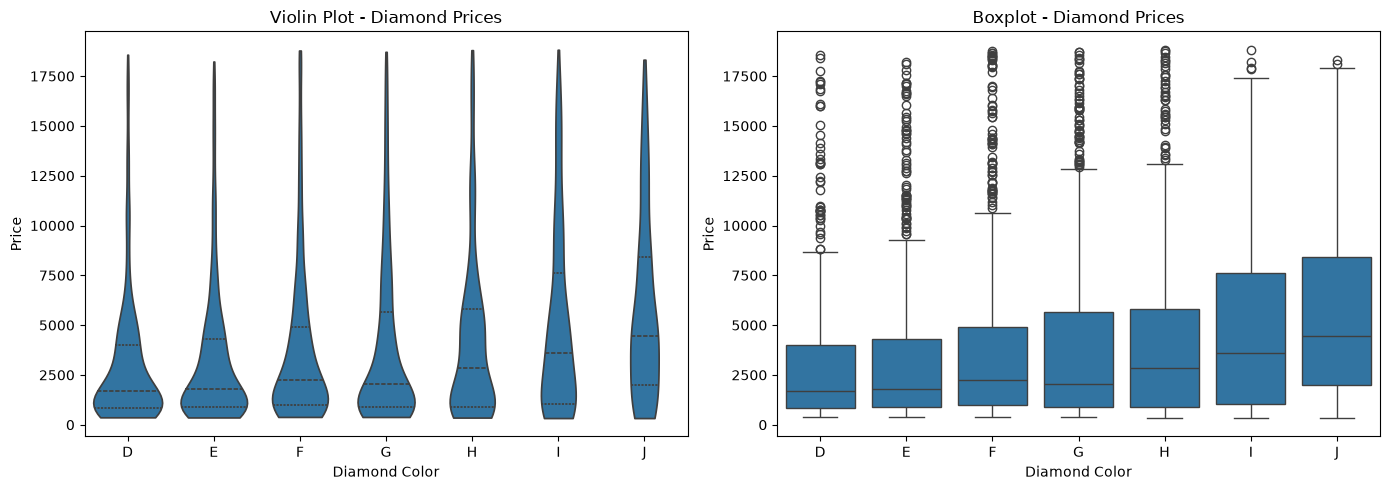

Comparison chart saved successfully!


In [3]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Violin plot
sns.violinplot(
    data=df,
    x="color",
    y="price",
    inner="quartile",
    cut=0,
    ax=axes[0]
)

axes[0].set_title("Violin Plot - Diamond Prices")
axes[0].set_xlabel("Diamond Color")
axes[0].set_ylabel("Price")

# Boxplot
sns.boxplot(
    data=df,
    x="color",
    y="price",
    ax=axes[1]
)

axes[1].set_title("Boxplot - Diamond Prices")
axes[1].set_xlabel("Diamond Color")
axes[1].set_ylabel("Price")

plt.tight_layout()
plt.savefig("diamonds_box_vs_violin.png", dpi=150)
plt.show()

print("Comparison chart saved successfully!")


Task 4: Log-price outlier analysis

DIAMOND OUTLIER SUMMARY
      cut  raw_price_outliers  log_price_outliers
     Fair                  15                   1
     Good                  32                   0
Very Good                  68                   0
  Premium                  81                   0
    Ideal                 142                   0


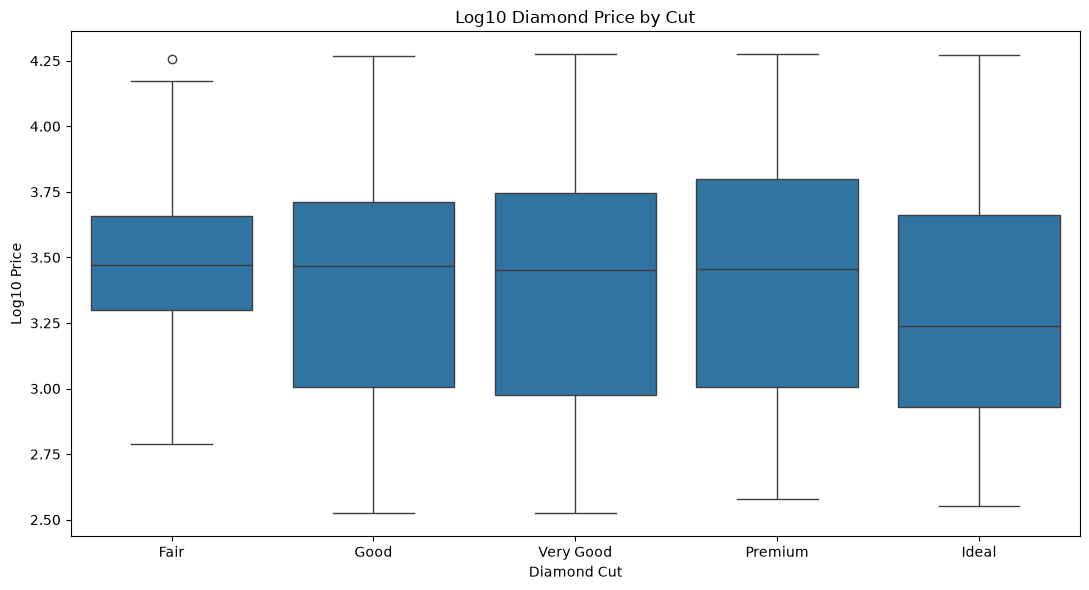

Session 4 completed successfully!


In [4]:

# Calculate log10 of diamond price
df["log_price"] = np.log10(df["price"])

# Calculate Q1 and Q3 for log price
log_q1 = df.groupby("cut", observed=True)["log_price"].transform(
    lambda x: x.quantile(0.25)
)

log_q3 = df.groupby("cut", observed=True)["log_price"].transform(
    lambda x: x.quantile(0.75)
)

log_iqr = log_q3 - log_q1

# Flag log-price outliers
df["log_outlier"] = (
    (df["log_price"] < log_q1 - 1.5 * log_iqr) |
    (df["log_price"] > log_q3 + 1.5 * log_iqr)
)

# Create summary table
outlier_summary = (
    df.groupby("cut", observed=True)
    .agg(
        raw_price_outliers=("price_outlier", "sum"),
        log_price_outliers=("log_outlier", "sum")
    )
    .reindex(cut_order)
    .reset_index()
)

print("DIAMOND OUTLIER SUMMARY")
print(outlier_summary.to_string(index=False))

outlier_summary.to_csv(
    "diamonds_outlier_summary.csv",
    index=False
)

# Create log-price boxplot
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="cut",
    y="log_price",
    order=cut_order
)

plt.title("Log10 Diamond Price by Cut")
plt.xlabel("Diamond Cut")
plt.ylabel("Log10 Price")

plt.tight_layout()
plt.savefig("diamonds_log_box.png", dpi=150)
plt.show()

print("Session 4 completed successfully!")
